(array([ 44172.,  76469.,  37730., 107618., 151736., 192215., 197668.,
        139091.,  34064.,  19237.]),
 array([0.96888072, 1.02042301, 1.07196529, 1.12350757, 1.17504985,
        1.22659213, 1.27813441, 1.32967669, 1.38121897, 1.43276125,
        1.48430353]),
 <BarContainer object of 10 artists>)

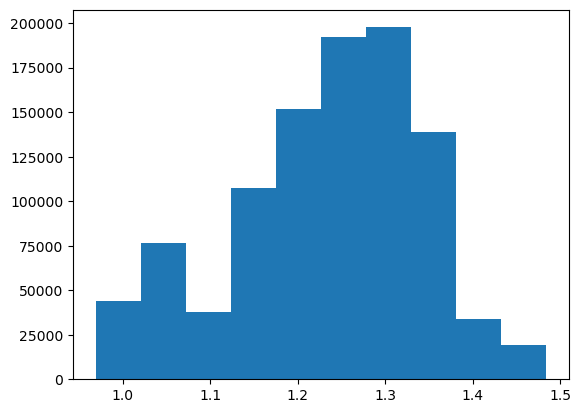

In [1]:
import numpy as np
import pandas as pd
from astropy.table import Table
import matplotlib.pyplot as plt

LSdata_df = pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})
LS_tab = Table.from_pandas(LSdata_df)
gehr_data = LS_tab[LS_tab['origin_id']==0.0]


# Simular datos a partir de las sigmas observadas. (Distribucion empirica)


logsigma_true = np.random.choice(
    gehr_data["log_sigma"],
    size=1000000,
    replace=True
) + np.random.uniform(0,0.07,1000000)

sigma_true = 10**logsigma_true 

plt.hist(logsigma_true)

(array([2., 5., 7., 3., 8., 9., 2., 3., 2., 2.]),
 array([-13.41585553, -13.09904402, -12.78223252, -12.46542101,
        -12.14860951, -11.831798  , -11.5149865 , -11.19817499,
        -10.88136349, -10.56455198, -10.24774047]),
 <BarContainer object of 10 artists>)

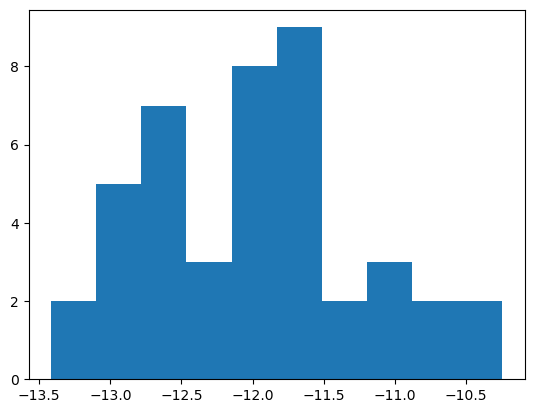

In [2]:
plt.hist(gehr_data["log_f_Hbeta"])

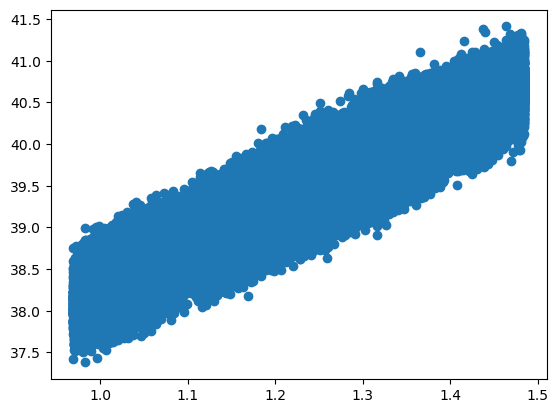

In [3]:
eps = np.random.normal(
    0.0,
    0.2,
    size=1000000
)

logL_true = (
    33.25
    + 5.02 * logsigma_true
    + eps
)

plt.scatter(logsigma_true,logL_true)

In [4]:
def simulate_GEHR_host(
    mu,
    alpha,
    beta,
    sigma_int,
    logsigma_reference,
    logsigma_error_real,
    logflux_error_real,
    N=500000,
    sigma_add_error=0.06,
):

    # -------------------------------
    # 1. Sigma latente
    # -------------------------------

    logsigma_true = np.random.choice(
        logsigma_reference,
        size=N,
        replace=True
    ) + np.random.uniform(0,sigma_add_error,N)

    sigma_true = 10**logsigma_true 


    # -------------------------------
    # 2. Scatter intrínseco
    # -------------------------------

    eps_int = np.random.normal(
        0.0,
        sigma_int,
        size=N
    )


    # -------------------------------
    # 3. L(Hbeta)
    # -------------------------------

    logL_true = (
        alpha
        + beta * logsigma_true
        + eps_int
    )


    # -------------------------------
    # 4. F(Hbeta)
    # log F = log L - 0.4 mu - 40.079
    # -------------------------------

    logF_true = (
        logL_true
        - 0.4 * mu
        - 40.079
    )

    flux_true = 10**logF_true

    # -------------------------------
    # 5. Log Sigma error
    # e~N(mean,stdev)
    # -------------------------------

    sigma_errors = np.asarray(logsigma_error_real, dtype=float)

    # Eliminar errores nulos, negativos, NaN e infinitos
    sigma_errors = sigma_errors[
        np.isfinite(sigma_errors) & (sigma_errors > 0)
    ]

    if len(sigma_errors) == 0:
        raise ValueError("No hay errores válidos de log_sigma")

    # Eliminar valores extremos (percentiles 1 y 99)
    if len(sigma_errors) >= 20:
        p1, p99 = np.percentile(sigma_errors, [1, 99])
        sigma_errors = sigma_errors[
            (sigma_errors >= p1) & (sigma_errors <= p99)
        ]

    logsigma_error = np.random.choice(
        sigma_errors, size=N, replace=True
    )




    # -------------------------------
    # 6. Log Flux error
    # e~N(mean,stdev)
    # -------------------------------

    flux_errors = np.asarray(logflux_error_real, dtype=float)

    flux_errors = flux_errors[
        np.isfinite(flux_errors) & (flux_errors > 0)
    ]

    if len(flux_errors) == 0:
        raise ValueError("No hay errores válidos de logflux")

    if len(flux_errors) >= 20:
        p1, p99 = np.percentile(flux_errors, [1, 99])
        flux_errors = flux_errors[
            (flux_errors >= p1) & (flux_errors <= p99)
        ]

    logflux_error = np.random.choice(
        flux_errors, size=N, replace=True
    )


    Mock_data = pd.DataFrame({
        "mu": mu,
        "sigma_kms": sigma_true,
        "LogSigma": logsigma_true,
        "LogSigma_e": logsigma_error,
        "LogL_Hb": logL_true,
        "LogFlux_Hb": logF_true,
        "LogFlux_e": logflux_error,
        "Flux_Hb": flux_true
    })

    return Mock_data.sample(n=10000)

<ErrorbarContainer object of 3 artists>

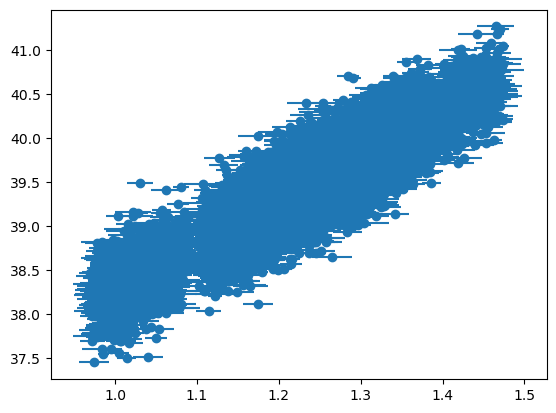

In [5]:
mock_Galaxy = simulate_GEHR_host(
    mu=33,
    alpha=33.25,
    beta=5.02,
    sigma_int=0.26,
    logsigma_reference=gehr_data["log_sigma"],
    logsigma_error_real = gehr_data["e_log_sigma"],
    logflux_error_real = gehr_data["e_log_f_Hbeta"],
)

mock_tab = mock_Galaxy

# 29.15 5.M101
# 29.15 5.M101
# 24.58 3.M33
# 29.80 7.NGC0925
# 27.63 8.NGC2366
# 27.49 9.NGC2403
# 30.35 10.NGC2541
# 30.65 12.NGC3319
# 29.8  15.NGC4258
# 28.22 16.NGC4395

plt.errorbar(mock_tab['LogSigma'],mock_tab['LogL_Hb'],xerr=mock_tab['LogSigma_e'],fmt='o')

(array([  37.,  289.,  731., 1100., 1967., 2573., 2189.,  878.,  216.,
          20.]),
 array([-15.82838653, -15.44699798, -15.06560942, -14.68422086,
        -14.30283231, -13.92144375, -13.5400552 , -13.15866664,
        -12.77727808, -12.39588953, -12.01450097]),
 <BarContainer object of 10 artists>)

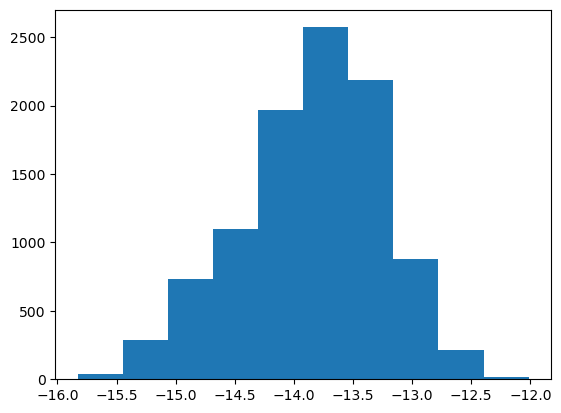

In [6]:
plt.hist(mock_tab['LogFlux_Hb'])

In [7]:
def simulate_GEHR_host(
    mu,
    alpha,
    beta,
    sigma_int,
    logsigma_reference,
    logsigma_error_real,
    logflux_error_real,
    N=500000,
    sigma_add_error=0.06,
):

    # -------------------------------
    # 1. Sigma latente
    # -------------------------------

    logsigma_true = np.random.choice(
        logsigma_reference,
        size=N,
        replace=True
    ) + np.random.uniform(0,sigma_add_error,N)

    sigma_true = 10**logsigma_true 


    # -------------------------------
    # 2. Scatter intrínseco
    # -------------------------------

    eps_int = np.random.normal(
        0.0,
        sigma_int,
        size=N
    )


    # -------------------------------
    # 3. L(Hbeta)
    # -------------------------------

    logL_true = (
        alpha
        + beta * logsigma_true
        + eps_int
    )


    # -------------------------------
    # 4. F(Hbeta)
    # log F = log L - 0.4 mu - 40.079
    # -------------------------------

    logF_true = (
        logL_true
        - 0.4 * mu
        - 40.079
    )

    flux_true = 10**logF_true

    # -------------------------------
    # 5. Log Sigma error
    # e~N(mean,stdev)
    # -------------------------------

    sigma_errors = np.asarray(logsigma_error_real, dtype=float)

    # Eliminar errores nulos, negativos, NaN e infinitos
    sigma_errors = sigma_errors[
        np.isfinite(sigma_errors) & (sigma_errors > 0)
    ]

    if len(sigma_errors) == 0:
        raise ValueError("No hay errores válidos de log_sigma")

    # Eliminar valores extremos (percentiles 1 y 99)
    if len(sigma_errors) >= 20:
        p1, p99 = np.percentile(sigma_errors, [1, 99])
        sigma_errors = sigma_errors[
            (sigma_errors >= p1) & (sigma_errors <= p99)
        ]

    logsigma_error = np.random.choice(
        sigma_errors, size=N, replace=True
    )




    # -------------------------------
    # 6. Log Flux error
    # e~N(mean,stdev)
    # -------------------------------

    flux_errors = np.asarray(logflux_error_real, dtype=float)

    flux_errors = flux_errors[
        np.isfinite(flux_errors) & (flux_errors > 0)
    ]

    if len(flux_errors) == 0:
        raise ValueError("No hay errores válidos de logflux")

    if len(flux_errors) >= 20:
        p1, p99 = np.percentile(flux_errors, [1, 99])
        flux_errors = flux_errors[
            (flux_errors >= p1) & (flux_errors <= p99)
        ]

    logflux_error = np.random.choice(
        flux_errors, size=N, replace=True
    )


    Mock_data = pd.DataFrame({
        "mu": mu,
        "sigma_kms": sigma_true,
        "LogSigma": logsigma_true,
        "LogSigma_e": logsigma_error,
        "LogL_Hb": logL_true,
        "LogFlux_Hb": logF_true,
        "LogFlux_e": logflux_error,
        "Flux_Hb": flux_true
    })

    return Mock_data.sample(n=1)

In [8]:
def group_reader(DF=None, group=None, error_kind = None, MOCK = 'A'):

    if DF is not None and group is not None and error_kind is not None:
        DF_pd = DF.to_pandas()
        df_group = pd.read_csv(group)
        galaxies_in_group = df_group['galaxy'].unique()
        filtro = DF_pd[DF_pd['GEHR_id'].isin(galaxies_in_group) | (DF_pd['origin_id'] > 0.0)].copy()
        filtro = filtro.merge(
            df_group[['galaxy', 'mu_W', f'{error_kind}']], 
            left_on='GEHR_id', 
            right_on='galaxy', 
            how='left'
        )
        coincide = filtro['mu_W'].notna()
        filtro.loc[coincide, 'z_or_mu'] = filtro.loc[coincide, 'mu_W']
        filtro.loc[coincide, 'e_z_or_e_mu'] = filtro.loc[coincide, f'{error_kind}']
        filtro = filtro.drop(columns=['galaxy', 'mu_W', f'{error_kind}'])
        
        filtro['Mock'] = False



        galaxies_in_DF = filtro[filtro['origin_id']==0.0]['GEHR_id'].unique()
        match = np.isin(galaxies_in_group,galaxies_in_DF)
        print('Galaxias en DF original: ', galaxies_in_DF)
        print('Galaxias en recal file: ', galaxies_in_group)
        print('Match: ', galaxies_in_group[match])
        print('Dismatch: ', galaxies_in_group[~match])

        reference = DF_pd[
            DF_pd['origin_id'] == 0.0
        ][[
            'log_sigma',
            'e_log_sigma',
            'e_log_f_Hbeta'
        ]].copy()



        if MOCK == 'A':
            print('10 nuevas GEHR en galaxias presentes')
            newGEHR_oldGAL = np.random.choice(galaxies_in_group[match], size=10, replace=True)

            for G in newGEHR_oldGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)

        if MOCK == 'B':
            print('10 nuevas GEHR en galaxias nuevas')
            newGEHR_newGAL = np.random.choice(galaxies_in_group[~match], size=10, replace=True)

            for G in newGEHR_newGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)


        if MOCK == 'C':
            print('30 nuevas GEHR en galaxias presentes')
            newGEHR_oldGAL = np.random.choice(galaxies_in_group[match], size=30, replace=True)

            for G in newGEHR_oldGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)

        if MOCK == 'D':
            print('30 nuevas GEHR en galaxias nuevas')
            newGEHR_newGAL = np.random.choice(galaxies_in_group[~match], size=30, replace=True)

            for G in newGEHR_newGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)

        # ============================================================
        # MOCK E, F, G
        # ============================================================

        if MOCK in ('E', 'F', 'G'):

            # Referencia: únicamente GEHR originalmente observadas.
            # Evitamos utilizar mocks recién generados como referencia.
            #reference = filtro[filtro['origin_id'] == 0.0].copy()

            # Índice único para cada nueva GEHR
            next_ix = int(filtro['index'].max()) + 1

            # Tabla de distancias por galaxia
            distance_table = (
                df_group.drop_duplicates(subset='galaxy')
                .set_index('galaxy')
            )

            # Función auxiliar para generar una GEHR
            def create_mock_GEHR(G, new_ix):

                if G not in distance_table.index:
                    raise ValueError(
                        f"La galaxia {G} no está en el archivo de anclas."
                    )

                mu = distance_table.at[G, 'mu_W']
                mu_e = distance_table.at[G, error_kind]

                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference=reference["log_sigma"],
                    logsigma_error_real=reference["e_log_sigma"],
                    logflux_error_real=reference["e_log_f_Hbeta"],
                )

                new_entry = pd.DataFrame([{
                    'index': new_ix,
                    'z_or_mu': mu,
                    'e_z_or_e_mu': mu_e,
                    'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                    'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                    'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                    'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                    'origin_id': 0.0,
                    'GEHR_id': G,
                    'Mock': True,
                }])

                return new_entry

            # ========================================================
            # MOCK E: Número fijo de nuevas GEHR por galaxia
            # ========================================================

            if MOCK == 'E':

                print('MOCK E: GEHR adicionales por galaxia')

                newGEHR_per_galaxy = {
                    "M66": 3,
                    "M96": 1,
                    "NGC1073": 4,
                    "NGC2500": 4,
                    "NGC2541": 1,
                    "NGC3198": 2,
                    "NGC3370": 3,
                    "NGC4214": 2,
                    "NGC4258": 1,
                    "NGC4414": 3,
                    "NGC4496A": 3,
                    "NGC4535": 2,
                    "NGC4536": 2,
                    "NGC4725": 1,
                    "NGC5204": 4,
                    "NGC5584": 3,
                    "NGC7331": 4,
                    "UGC08091": 2,
                    "UGC09128": 1

                    # Agregar más galaxias...
                }

                for G, n_new in newGEHR_per_galaxy.items():

                    if G not in distance_table.index:
                        print(f"[SKIP] {G}: no está en el archivo de anclas.")
                        continue                    

                    print(f"{G}: agregando {n_new} GEHR")

                    if not isinstance(n_new, (int, np.integer)) or n_new < 0:
                        raise ValueError(
                            f"Número inválido de GEHR para {G}: {n_new}"
                        )

                    for _ in range(n_new):

                        new_entry = create_mock_GEHR(G, next_ix)

                        filtro = pd.concat(
                            [filtro, new_entry],
                            ignore_index=True
                        )

                        next_ix += 1


            # ========================================================
            # MOCK F: Exactamente 2 GEHR por galaxia
            # MOCK G: Exactamente 5 GEHR por galaxia
            # Incluye galaxias sin GEHR originalmente observadas
            # ========================================================

            if MOCK in ('F', 'G'):

                target = 2 if MOCK == 'F' else 5

                print(
                    f'MOCK {MOCK}: {target} GEHR por galaxia anfitriona'
                )

                rng = np.random.default_rng(42)

                # Recorrer TODAS las galaxias del archivo de anclas,
                # incluso aquellas sin GEHR observadas.
                for G in galaxies_in_group:

                    # Identificar GEHR originales de esta galaxia
                    idx = filtro.index[
                        (filtro['origin_id'] == 0.0) &
                        (filtro['GEHR_id'] == G)
                    ].to_numpy()

                    n_obs = len(idx)

                    # CASO 1: Hay más GEHR observadas que el objetivo
                    if n_obs > target:

                        n_remove = n_obs - target

                        drop_idx = rng.choice(
                            idx,
                            size=n_remove,
                            replace=False
                        )

                        filtro = filtro.drop(index=drop_idx)

                        print(
                            f"{G}: {n_obs} observadas -> "
                            f"{target} conservadas"
                        )

                    # CASO 2: Hay menos GEHR que el objetivo
                    # Incluye galaxias con 0 GEHR observadas
                    elif n_obs < target:

                        n_new = target - n_obs

                        for _ in range(n_new):

                            new_entry = create_mock_GEHR(G, next_ix)

                            filtro = pd.concat(
                                [filtro, new_entry],
                                ignore_index=True
                            )

                            next_ix += 1

                        print(
                            f"{G}: {n_obs} observadas + "
                            f"{n_new} simuladas = {target}"
                        )

                    # CASO 3: Ya tiene exactamente el número deseado
                    else:

                        print(
                            f"{G}: {target} observadas, sin cambios"
                        )

                filtro = filtro.reset_index(drop=True)




        new_DF = Table.from_pandas(filtro)
        return new_DF
    else:
        return None

In [7]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='A'
).to_pandas().to_csv('MockA.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
10 nuevas GEHR en galaxias presentes


In [8]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='B'
).to_pandas().to_csv('MockB.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
10 nuevas GEHR en galaxias nuevas


In [9]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='C'
).to_pandas().to_csv('MockC.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
30 nuevas GEHR en galaxias presentes


In [10]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='D'
).to_pandas().to_csv('MockD.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
30 nuevas GEHR en galaxias nuevas


In [13]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'PLRC_all_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='E'
).to_pandas().to_csv('MockE.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'NGC6822']
Galaxias en recal file:  ['IC0010' 'NGC2366' 'NGC4395' 'MRK116' 'NGC2403' 'NGC3319' 'NGC0925' 'M81'
 'NGC2541' 'NGC3198' 'M96' 'NGC6822' 'M33' 'M101' 'NGC4258' 'M66'
 'NGC3370' 'NGC4725' 'NGC4535' 'NGC4414' 'NGC7331' 'NGC5584' 'NGC4496A'
 'NGC4536']
Match:  ['IC0010' 'NGC2366' 'NGC4395' 'MRK116' 'NGC2403' 'NGC3319' 'NGC0925' 'M81'
 'NGC2541' 'NGC3198' 'NGC6822' 'M33' 'M101' 'NGC4258']
Dismatch:  ['M96' 'M66' 'NGC3370' 'NGC4725' 'NGC4535' 'NGC4414' 'NGC7331' 'NGC5584'
 'NGC4496A' 'NGC4536']
MOCK E: GEHR adicionales por galaxia
M66: agregando 3 GEHR
M96: agregando 1 GEHR
[SKIP] NGC1073: no está en el archivo de anclas.
[SKIP] NGC2500: no está en el archivo de anclas.
NGC2541: agregando 1 GEHR
NGC3198: agregando 2 GEHR
NGC3370: agregando 3 GEHR
[SKIP] NGC4214: no está en el archivo de anclas.
NGC4258: agregando 1 GEHR
NGC4414: agregand

In [5]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'TRGB_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='F'
).to_pandas().to_csv('MockF.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC4258'
 'NGC4395' 'IC2574' 'NGC4214' 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC4236' 'NGC1073' 'NGC2500' 'NGC2366' 'NGC4395' 'IC2574'
 'NGC4214' 'NGC4258' 'NGC2403' 'M81' 'IC0010' 'M33' 'M101' 'NGC6822' 'M96'
 'NGC5204' 'NGC3370' 'M66' 'UGC08091' 'NGC5584' 'UGC09128']
Match:  ['MRK116' 'NGC4236' 'NGC2366' 'NGC4395' 'IC2574' 'NGC4214' 'NGC4258'
 'NGC2403' 'M81' 'IC0010' 'M33' 'M101' 'NGC6822']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'NGC5204' 'NGC3370' 'M66' 'UGC08091' 'NGC5584'
 'UGC09128']
MOCK F: 2 GEHR por galaxia anfitriona
MRK116: 1 observadas + 1 simuladas = 2
NGC4236: 2 observadas, sin cambios
NGC1073: 0 observadas + 2 simuladas = 2
NGC2500: 0 observadas + 2 simuladas = 2
NGC2366: 4 observadas -> 2 conservadas
NGC4395: 3 observadas -> 2 conservadas
IC2574: 2 observadas, sin cambios
NGC4214: 1 observadas + 1 simuladas = 2
NGC4258: 2 observadas, sin cambios
NGC2403: 3 observadas 

In [6]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'TRGB_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='G'
).to_pandas().to_csv('MockG.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC4258'
 'NGC4395' 'IC2574' 'NGC4214' 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC4236' 'NGC1073' 'NGC2500' 'NGC2366' 'NGC4395' 'IC2574'
 'NGC4214' 'NGC4258' 'NGC2403' 'M81' 'IC0010' 'M33' 'M101' 'NGC6822' 'M96'
 'NGC5204' 'NGC3370' 'M66' 'UGC08091' 'NGC5584' 'UGC09128']
Match:  ['MRK116' 'NGC4236' 'NGC2366' 'NGC4395' 'IC2574' 'NGC4214' 'NGC4258'
 'NGC2403' 'M81' 'IC0010' 'M33' 'M101' 'NGC6822']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'NGC5204' 'NGC3370' 'M66' 'UGC08091' 'NGC5584'
 'UGC09128']
MOCK G: 5 GEHR por galaxia anfitriona
MRK116: 1 observadas + 4 simuladas = 5
NGC4236: 2 observadas + 3 simuladas = 5
NGC1073: 0 observadas + 5 simuladas = 5
NGC2500: 0 observadas + 5 simuladas = 5
NGC2366: 4 observadas + 1 simuladas = 5
NGC4395: 3 observadas + 2 simuladas = 5
IC2574: 2 observadas + 3 simuladas = 5
NGC4214: 1 observadas + 4 simuladas = 5
NGC4258: 2 observadas + 3 simuladas = 5
NGC24

In [35]:
def group_reader(DF=None, group=None, error_kind = None, MOCK = 'A'):

    if DF is not None and group is not None and error_kind is not None:
        DF_pd = DF.to_pandas()
        df_group = pd.read_csv(group)
        galaxies_in_group = df_group['galaxy'].unique()
        filtro = DF_pd[DF_pd['GEHR_id'].isin(galaxies_in_group) | (DF_pd['origin_id'] > 0.0)].copy()
        filtro = filtro.merge(
            df_group[['galaxy', 'mu_W', f'{error_kind}']], 
            left_on='GEHR_id', 
            right_on='galaxy', 
            how='left'
        )
        coincide = filtro['mu_W'].notna()
        filtro.loc[coincide, 'z_or_mu'] = filtro.loc[coincide, 'mu_W']
        filtro.loc[coincide, 'e_z_or_e_mu'] = filtro.loc[coincide, f'{error_kind}']
        filtro = filtro.drop(columns=['galaxy', 'mu_W', f'{error_kind}'])
        
        filtro['Mock'] = False



        galaxies_in_DF = filtro[filtro['origin_id']==0.0]['GEHR_id'].unique()
        match = np.isin(galaxies_in_group,galaxies_in_DF)
        print('Galaxias en DF original: ', galaxies_in_DF)
        print('Galaxias en recal file: ', galaxies_in_group)
        print('Match: ', galaxies_in_group[match])
        print('Dismatch: ', galaxies_in_group[~match])

        reference = DF_pd[
            DF_pd['origin_id'] == 0.0
        ][[
            'log_sigma',
            'e_log_sigma',
            'e_log_f_Hbeta'
        ]].copy()


        newGEHR_per_galaxy = {
            "M66": 3,
            "M96": 1,
            "NGC1073": 4,
            "NGC2500": 4,
            "NGC2541": 1,
            "NGC3198": 2,
            "NGC3370": 3,
            "NGC4214": 2,
            "NGC4258": 1,
            "NGC4414": 3,
            "NGC4496A": 3,
            "NGC4535": 2,
            "NGC4536": 2,
            "NGC4725": 1,
            "NGC5204": 4,
            "NGC5584": 3,
            "NGC7331": 4,
            "UGC08091": 2,
            "UGC09128": 1

            # Agregar más galaxias...
        }

        selected_hosts = [
            "IC0010",
            "M33",
            "M81",
            "M101",
            "MRK116",
            "NGC2366",
            "NGC2403",
            "NGC4258",
            "NGC4395",
            "NGC6822",
            "M96",
            "NGC3370",
            "M66",
            "NGC5584",
            # Agregar más galaxias...
        ]


        if MOCK == 'A':
            print('10 nuevas GEHR en galaxias presentes')
            newGEHR_oldGAL = np.random.choice(galaxies_in_group[match], size=10, replace=True)

            for G in newGEHR_oldGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)

        if MOCK == 'B':
            print('10 nuevas GEHR en galaxias nuevas')
            newGEHR_newGAL = np.random.choice(galaxies_in_group[~match], size=10, replace=True)

            for G in newGEHR_newGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)


        if MOCK == 'C':
            print('30 nuevas GEHR en galaxias presentes')
            newGEHR_oldGAL = np.random.choice(galaxies_in_group[match], size=30, replace=True)

            for G in newGEHR_oldGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)

        if MOCK == 'D':
            print('30 nuevas GEHR en galaxias nuevas')
            newGEHR_newGAL = np.random.choice(galaxies_in_group[~match], size=30, replace=True)

            for G in newGEHR_newGAL:
                new_ix = filtro['index'].iloc[-1] + 1
                mu = df_group[df_group['galaxy']== G]['mu_W'].iloc[0]
                mu_e = df_group[df_group['galaxy']== G]['sigma_W'].iloc[0]

                
                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference = reference["log_sigma"],
                    logsigma_error_real = reference["e_log_sigma"],
                    logflux_error_real = reference["e_log_f_Hbeta"],
                    )       

                new_entry = pd.DataFrame([{'index': new_ix, 
                                             'z_or_mu': mu,
                                             'e_z_or_e_mu': mu_e,
                                             'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                                             'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                                             'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                                             'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                                             'origin_id': 0.0,
                                             'GEHR_id': G,
                                             'Mock': True,}])

                filtro = pd.concat([filtro, new_entry], ignore_index=True)

        # ============================================================
        # MOCK E, F, G, H, I, J
        # ============================================================

        if MOCK in ('E', 'F', 'G', 'H', 'I', 'J'):

            # Referencia: únicamente GEHR originalmente observadas.
            # Evitamos utilizar mocks recién generados como referencia.
            #reference = filtro[filtro['origin_id'] == 0.0].copy()

            # Índice único para cada nueva GEHR
            next_ix = int(filtro['index'].max()) + 1

            # Tabla de distancias por galaxia
            distance_table = (
                df_group.drop_duplicates(subset='galaxy')
                .set_index('galaxy')
            )

            # Función auxiliar para generar una GEHR
            def create_mock_GEHR(G, new_ix):

                if G not in distance_table.index:
                    raise ValueError(
                        f"La galaxia {G} no está en el archivo de anclas."
                    )

                mu = distance_table.at[G, 'mu_W']
                mu_e = distance_table.at[G, error_kind]

                mock_GEHR = simulate_GEHR_host(
                    mu=mu,
                    alpha=33.25,
                    beta=5.02,
                    sigma_int=0.26,
                    logsigma_reference=reference["log_sigma"],
                    logsigma_error_real=reference["e_log_sigma"],
                    logflux_error_real=reference["e_log_f_Hbeta"],
                )

                new_entry = pd.DataFrame([{
                    'index': new_ix,
                    'z_or_mu': mu,
                    'e_z_or_e_mu': mu_e,
                    'log_sigma': mock_GEHR['LogSigma'].iloc[0],
                    'e_log_sigma': mock_GEHR['LogSigma_e'].iloc[0],
                    'log_f_Hbeta': mock_GEHR['LogFlux_Hb'].iloc[0],
                    'e_log_f_Hbeta': mock_GEHR['LogFlux_e'].iloc[0],
                    'origin_id': 0.0,
                    'GEHR_id': G,
                    'Mock': True,
                }])

                return new_entry

            # ========================================================
            # MOCK E: Número fijo de nuevas GEHR por galaxia
            # ========================================================

            if MOCK == 'E':

                print('MOCK E: GEHR adicionales por galaxia')

                for G, n_new in newGEHR_per_galaxy.items():

                    if G not in distance_table.index:
                        print(f"[SKIP] {G}: no está en el archivo de anclas.")
                        continue                    

                    print(f"{G}: agregando {n_new} GEHR")

                    if not isinstance(n_new, (int, np.integer)) or n_new < 0:
                        raise ValueError(
                            f"Número inválido de GEHR para {G}: {n_new}"
                        )

                    for _ in range(n_new):

                        new_entry = create_mock_GEHR(G, next_ix)

                        filtro = pd.concat(
                            [filtro, new_entry],
                            ignore_index=True
                        )

                        next_ix += 1


            # ========================================================
            # MOCK F: Exactamente 2 GEHR por galaxia
            # MOCK G: Exactamente 5 GEHR por galaxia
            # Incluye galaxias sin GEHR originalmente observadas
            # ========================================================

            if MOCK in ('F', 'G'):

                target = 2 if MOCK == 'F' else 5

                print(
                    f'MOCK {MOCK}: {target} GEHR por galaxia anfitriona'
                )

                rng = np.random.default_rng(42)

                # Recorrer TODAS las galaxias del archivo de anclas,
                # incluso aquellas sin GEHR observadas.
                for G in galaxies_in_group:

                    # Identificar GEHR originales de esta galaxia
                    idx = filtro.index[
                        (filtro['origin_id'] == 0.0) &
                        (filtro['GEHR_id'] == G)
                    ].to_numpy()

                    n_obs = len(idx)

                    # CASO 1: Hay más GEHR observadas que el objetivo
                    if n_obs > target:

                        n_remove = n_obs - target

                        drop_idx = rng.choice(
                            idx,
                            size=n_remove,
                            replace=False
                        )

                        filtro = filtro.drop(index=drop_idx)

                        print(
                            f"{G}: {n_obs} observadas -> "
                            f"{target} conservadas"
                        )

                    # CASO 2: Hay menos GEHR que el objetivo
                    # Incluye galaxias con 0 GEHR observadas
                    elif n_obs < target:

                        n_new = target - n_obs

                        for _ in range(n_new):

                            new_entry = create_mock_GEHR(G, next_ix)

                            filtro = pd.concat(
                                [filtro, new_entry],
                                ignore_index=True
                            )

                            next_ix += 1

                        print(
                            f"{G}: {n_obs} observadas + "
                            f"{n_new} simuladas = {target}"
                        )

                    # CASO 3: Ya tiene exactamente el número deseado
                    else:

                        print(
                            f"{G}: {target} observadas, sin cambios"
                        )

                filtro = filtro.reset_index(drop=True)





            if MOCK in ('H', 'I', 'J'):
                gehr_mask = (
                    (DF_pd['origin_id'] == 0.0) &
                    (DF_pd['GEHR_id'].isin(selected_hosts))
                )
            else:
                gehr_mask = (
                    (DF_pd['origin_id'] == 0.0) &
                    (DF_pd['GEHR_id'].isin(galaxies_in_group))
                )

            filtro = DF_pd[
                gehr_mask | (DF_pd['origin_id'] > 0.0)
            ].copy()

            # ========================================================
            # MOCK H: Solo GEHR observadas de galaxias seleccionadas
            # ========================================================

            if MOCK == 'H':

                print('MOCK H: GEHR observadas en galaxias seleccionadas')

                for G in selected_hosts:

                    n_obs = len(filtro[
                        (filtro['origin_id'] == 0.0) &
                        (filtro['GEHR_id'] == G)
                    ])

                    if n_obs > 0:
                        print(f"{G}: {n_obs} GEHR observadas")
                    else:
                        print(f"[SKIP] {G}: sin GEHR observadas")


            # ========================================================
            # MOCK I: Galaxias seleccionadas + GEHR simuladas
            # en galaxias sin observaciones
            # ========================================================

            if MOCK == 'I':

                print('MOCK I: Galaxias seleccionadas con simulaciones adicionales')

                for G in selected_hosts:

                    n_obs = len(filtro[
                        (filtro['origin_id'] == 0.0) &
                        (filtro['GEHR_id'] == G)
                    ])

                    # Si tiene observaciones, conservarlas sin añadir mocks
                    if n_obs > 0:
                        print(f"{G}: {n_obs} GEHR observadas")
                        continue

                    # Solo simular si existe distancia de calibración
                    if G not in distance_table.index:
                        print(f"[SKIP] {G}: sin datos en df_group")
                        continue

                    # Número de GEHR especificado en el diccionario
                    n_new = newGEHR_per_galaxy.get(G, 0)

                    if not isinstance(n_new, (int, np.integer)) or n_new < 0:
                        raise ValueError(
                            f"Número de GEHR inválido para {G}: {n_new}"
                        )

                    for _ in range(n_new):

                        new_entry = create_mock_GEHR(G, next_ix)

                        filtro = pd.concat(
                            [filtro, new_entry],
                            ignore_index=True
                        )

                        next_ix += 1

                    print(f"{G}: 0 observadas + {n_new} simuladas")


            # ========================================================
            # MOCK J: Exactamente 4 GEHR por galaxia seleccionada
            # con distancia disponible en df_group
            # ========================================================

            if MOCK == 'J':

                target = 4

                print('MOCK J: 4 GEHR por galaxia seleccionada')

                rng = np.random.default_rng(42)

                for G in selected_hosts:

                    # Sin distancia de calibración no se pueden
                    # generar mocks. Se conservan sus observaciones.
                    if G not in distance_table.index:
                        print(f"[SKIP] {G}: sin distancia en df_group")
                        continue

                    idx = filtro.index[
                        (filtro['origin_id'] == 0.0) &
                        (filtro['GEHR_id'] == G)
                    ].to_numpy()

                    n_obs = len(idx)

                    # CASO 1: Más de 4 GEHR observadas
                    if n_obs > target:

                        n_remove = n_obs - target

                        drop_idx = rng.choice(
                            idx,
                            size=n_remove,
                            replace=False
                        )

                        filtro = filtro.drop(index=drop_idx)

                        print(
                            f"{G}: {n_obs} observadas -> "
                            f"{target} conservadas"
                        )

                    # CASO 2: Menos de 4 GEHR observadas
                    elif n_obs < target:

                        n_new = target - n_obs

                        for _ in range(n_new):

                            new_entry = create_mock_GEHR(G, next_ix)

                            filtro = pd.concat(
                                [filtro, new_entry],
                                ignore_index=True
                            )

                            next_ix += 1

                        print(
                            f"{G}: {n_obs} observadas + "
                            f"{n_new} simuladas = {target}"
                        )

                    # CASO 3: Exactamente 4 GEHR observadas
                    else:

                        print(f"{G}: {target} observadas, sin cambios")

                filtro = filtro.reset_index(drop=True)


        new_DF = Table.from_pandas(filtro)
        return new_DF
    else:
        return None

In [32]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='H'
).to_pandas().to_csv('MockH.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
MOCK H: GEHR observadas en galaxias seleccionadas
IC0010: 2 GEHR observadas
M33: 4 GEHR observadas
M81: 2 GEHR observadas
M101: 5 GEHR observadas
MRK116: 1

In [33]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='I'
).to_pandas().to_csv('MockI.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
MOCK I: Galaxias seleccionadas con simulaciones adicionales
IC0010: 2 GEHR observadas
M33: 4 GEHR observadas
M81: 2 GEHR observadas
M101: 5 GEHR observadas

In [34]:
concat_filter_DF = group_reader(
    DF = Table.from_pandas(pd.read_csv('Compilation2026_whole.csv',comment='#',index_col=False, dtype={'GEHR_id': str})),
    group = 'Joint_eR_recal.csv',
    error_kind = 'sigma_W', MOCK='J'
).to_pandas().to_csv('MockJ.csv')

Galaxias en DF original:  ['IC0010' 'M101' 'M33' 'M81' 'MRK116' 'NGC2366' 'NGC2403' 'NGC0925'
 'NGC4258' 'NGC4395' 'NGC2541' 'NGC3319' 'NGC3198' 'IC2574' 'NGC4214'
 'NGC4236' 'NGC6822']
Galaxias en recal file:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'NGC1073' 'NGC2500' 'M33' 'M101' 'NGC4236'
 'NGC4214' 'NGC4395' 'M96' 'NGC6822' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370'
 'NGC4535' 'NGC4258' 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128'
 'NGC7331' 'NGC5584']
Match:  ['MRK116' 'NGC2541' 'NGC0925' 'NGC2403' 'NGC3198' 'NGC2366' 'NGC3319'
 'M81' 'IC2574' 'IC0010' 'M33' 'M101' 'NGC4236' 'NGC4214' 'NGC4395'
 'NGC6822' 'NGC4258']
Dismatch:  ['NGC1073' 'NGC2500' 'M96' 'M66' 'NGC4496A' 'NGC4414' 'NGC3370' 'NGC4535'
 'NGC4536' 'NGC4725' 'UGC08091' 'NGC5204' 'UGC09128' 'NGC7331' 'NGC5584']
MOCK J: 4 GEHR por galaxia seleccionada
IC0010: 2 observadas + 2 simuladas = 4
M33: 4 observadas, sin cambios
M81: 2 observadas + 2 simuladas = 4
M101: 5 o